# Эксперименты и сравнение конфигураций

В ноутбуке выполняются 20 независимых запусков каждой конфигурации с `seed = 1000, …, 1019`. Все методы получают ровно 10 000 вычислений функции, включая начальную популяцию генетического алгоритма.

Первая кодовая ячейка выполняет `01_genetic_algorithm.ipynb`, поэтому оба файла нужно хранить в одном каталоге. Это позволяет переиспользовать реализацию без отдельного Python-модуля и без копирования кода.

Лучшее значение: -8.319071
Вычислений функции: 10000 из 10000
Лучшая точка: [2.2021 1.5703 1.2861 1.1121 0.9953 1.571  1.8776 2.078  1.6561]


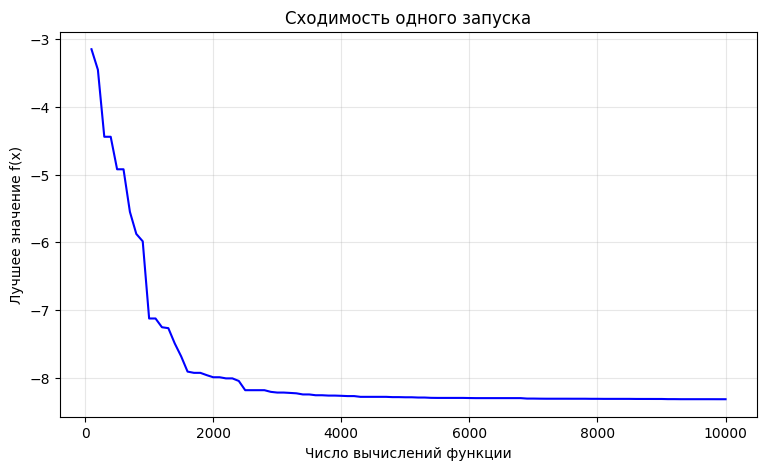

In [1]:
%matplotlib inline
%run "01_genetic_algorithm.ipynb"


## План эксперимента

Базовая конфигурация (`GA_base`) использует SBX и адаптацию $\sigma$. В каждой альтернативе меняется ровно один фактор:

- `GA_SBX_fixed_sigma`: адаптация $\sigma$ отключена, масштаб мутации фиксирован;
- `GA_SBX_small_pop`: размер популяции уменьшен со 100 до 30;
- `GA_SBX_large_sigma`: начальное $\sigma$ увеличено с 0.1 до 0.3;
- `GA_arithmetic`: SBX заменён арифметическим кроссовером;
- `GA_BLX`: SBX заменён BLX-кроссовером.

Адаптация $\sigma$ остаётся включённой во всех конфигурациях, кроме `GA_SBX_fixed_sigma`. Случайный поиск сравнивается с базовой конфигурацией при том же бюджете.

In [2]:
import json
from collections.abc import Callable
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path("results")
PLOTS_DIR = Path("plots")
CONFIGS_DIR = Path("configs")

N_RUNS = 20
BASE_SEED = 1000

base_config = GAConfig(
    population_size=100,
    budget=10_000,
    crossover="sbx",
    selection="tournament",
    mutation_prob=0.1,
    mutation_sigma=0.1,
    adaptive_sigma=True,
    seed=BASE_SEED,
)

configs = {
    "GA_base": base_config,
    "GA_SBX_fixed_sigma": replace(base_config, adaptive_sigma=False),
    "GA_SBX_small_pop": replace(base_config, population_size=30),
    "GA_SBX_large_sigma": replace(base_config, mutation_sigma=0.3),
    "GA_arithmetic": replace(base_config, crossover="arithmetic"),
    "GA_BLX": replace(base_config, crossover="blx"),
}


## Вспомогательные функции

Одна функция `run_series` обслуживает ГА и случайный поиск: алгоритм передаётся как функция, принимающая конфигурацию. Для каждого запуска создаётся независимая копия конфигурации с новым `seed`.

Графики сходимости строятся по фактическому числу вычислений функции. Это даёт одинаковую горизонтальную шкалу для ГА с разными размерами популяций и для случайного поиска.

In [3]:
def run_ga(config: GAConfig) -> dict:
    return GeneticAlgorithm(config).run()


def run_series(
    run_once: Callable[[GAConfig], dict],
    config: GAConfig,
    n_runs: int = N_RUNS,
    base_seed: int = BASE_SEED,
) -> list[dict]:
    results = []
    for run in range(n_runs):
        cfg = replace(config, seed=base_seed + run)
        result = run_once(cfg)
        result["run"] = run
        result["seed"] = cfg.seed
        result["config"] = asdict(cfg)
        results.append(result)
    return results


def series_to_dataframe(results: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "run": result["run"],
                "seed": result["seed"],
                "best_fitness": result["best_fitness"],
                "n_evals": result["n_evals"],
            }
            for result in results
        ]
    )


def summarize(df: pd.DataFrame) -> dict:
    return {
        "best": float(df["best_fitness"].min()),
        "mean": float(df["best_fitness"].mean()),
        "median": float(df["best_fitness"].median()),
        "std": float(df["best_fitness"].std(ddof=1)),
        "worst": float(df["best_fitness"].max()),
    }


def save_json(data: dict, path: Path) -> None:
    text = json.dumps(data, ensure_ascii=False, indent=2)
    path.write_text(text + "\n", encoding="utf-8")


In [4]:
def plot_convergence(results: list[dict], title: str, path: Path) -> None:
    histories = np.asarray([result["best_history"] for result in results])
    evaluations = np.asarray(results[0]["eval_history"])
    mean = histories.mean(axis=0)
    std = histories.std(axis=0, ddof=1)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(evaluations, mean, label="Среднее", color="blue")
    ax.fill_between(
        evaluations,
        mean - std,
        mean + std,
        alpha=0.2,
        color="blue",
        label="±1 стандартное отклонение",
    )
    ax.plot(
        evaluations,
        histories.min(axis=0),
        label="Минимум",
        color="green",
        linestyle="--",
    )
    ax.plot(
        evaluations,
        histories.max(axis=0),
        label="Максимум",
        color="red",
        linestyle="--",
    )
    ax.set_xlabel("Число вычислений функции")
    ax.set_ylabel("Лучшее значение f(x)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)


def plot_comparison(summaries: dict[str, dict], path: Path) -> None:
    names = list(summaries)
    means = [summaries[name]["mean"] for name in names]
    stds = [summaries[name]["std"] for name in names]
    bests = [summaries[name]["best"] for name in names]
    x = np.arange(len(names))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(
        x - width / 2,
        means,
        width,
        yerr=stds,
        label="Среднее ± стандартное отклонение",
        capsize=5,
        alpha=0.7,
    )
    ax.bar(x + width / 2, bests, width, label="Лучшее", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=15, ha="right")
    ax.set_ylabel("f(x)")
    ax.set_title(f"Сравнение конфигураций по серии из {N_RUNS} запусков")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)


## Запуск серий

Полное выполнение следующей ячейки занимает некоторое время. Результаты сохраняются в `results/`, конфигурации — в `configs/`, графики — в `plots/`.

In [5]:
for directory in (RESULTS_DIR, PLOTS_DIR, CONFIGS_DIR):
    directory.mkdir(exist_ok=True)

save_json(asdict(base_config), CONFIGS_DIR / "base.json")
for name, cfg in configs.items():
    save_json(asdict(cfg), CONFIGS_DIR / f"{name}.json")

all_results = {}
for name, cfg in configs.items():
    print(f"Выполняется {name}...")
    all_results[name] = run_series(run_ga, cfg)

print("Выполняется RandomSearch...")
all_results["RandomSearch"] = run_series(random_search, base_config)


Выполняется GA_base...


Выполняется GA_SBX_fixed_sigma...


Выполняется GA_SBX_small_pop...


Выполняется GA_SBX_large_sigma...


Выполняется GA_arithmetic...


Выполняется GA_BLX...


Выполняется RandomSearch...


## Статистика

Для каждой серии вычисляются лучший, средний, медианный и худший результат, а также выборочное стандартное отклонение. Для минимизации более низкие значения лучше.

In [6]:
all_summaries = {}
for name, results in all_results.items():
    df = series_to_dataframe(results)
    df.to_csv(RESULTS_DIR / f"{name}.csv", index=False)
    all_summaries[name] = summarize(df)

summary_df = pd.DataFrame(all_summaries).T
summary_df.index.name = "config"
summary_df.to_csv(RESULTS_DIR / "summary.csv")
save_json(all_results, RESULTS_DIR / "all_results.json")
display(summary_df.round(4))


,best,mean,median,std,worst
config,,,,,
GA_base,-8.5804,-8.2614,-8.2552,0.2029,-7.9441
GA_SBX_fixed_sigma,-8.6198,-8.2763,-8.3340,0.2179,-7.8516
GA_SBX_small_pop,-8.3530,-7.7456,-7.8161,0.4988,-6.5668
GA_SBX_large_sigma,-8.6556,-8.5352,-8.5896,0.1243,-8.1992
GA_arithmetic,-8.6190,-8.2594,-8.3635,0.3461,-7.1823
GA_BLX,-8.6538,-8.1685,-8.1959,0.2545,-7.7341
RandomSearch,-5.7365,-4.5852,-4.4726,0.4120,-4.0830


## Графики сходимости

На каждом графике показаны средняя траектория, диапазон ±1 стандартное отклонение, а также минимум и максимум по 20 запускам. Последние две линии описывают разброс между запусками, а не доверительный интервал для среднего.

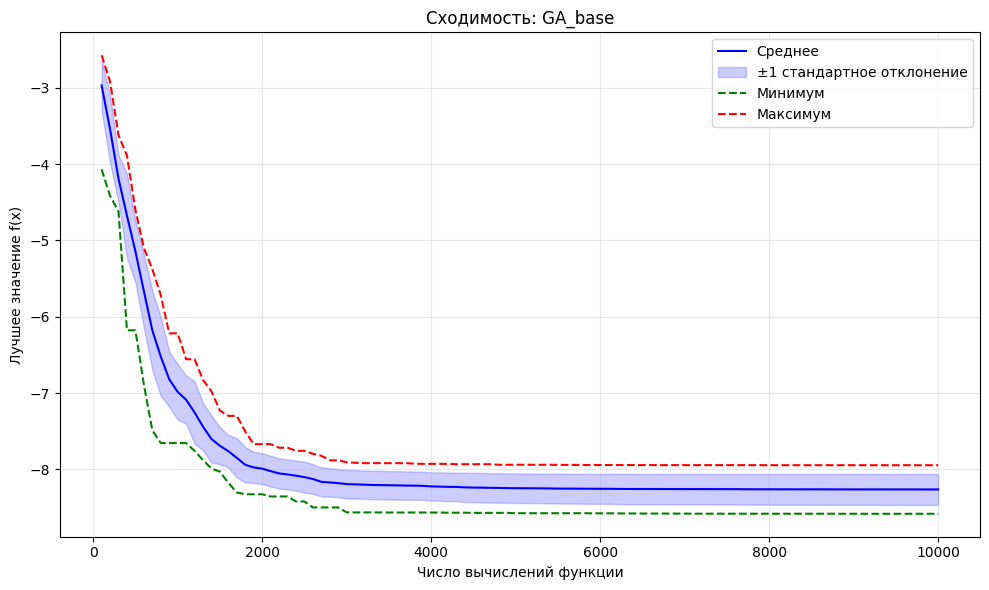

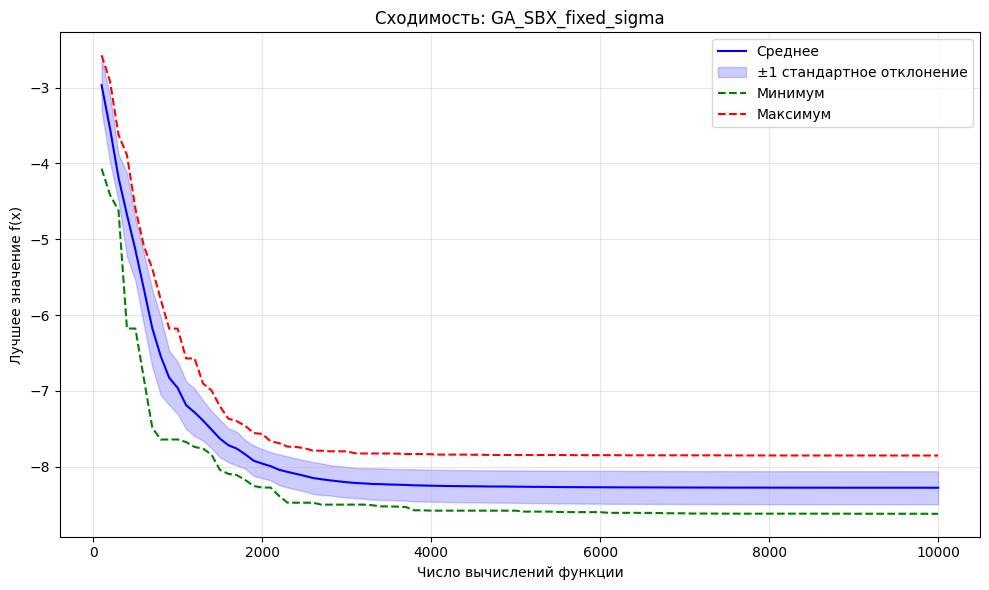

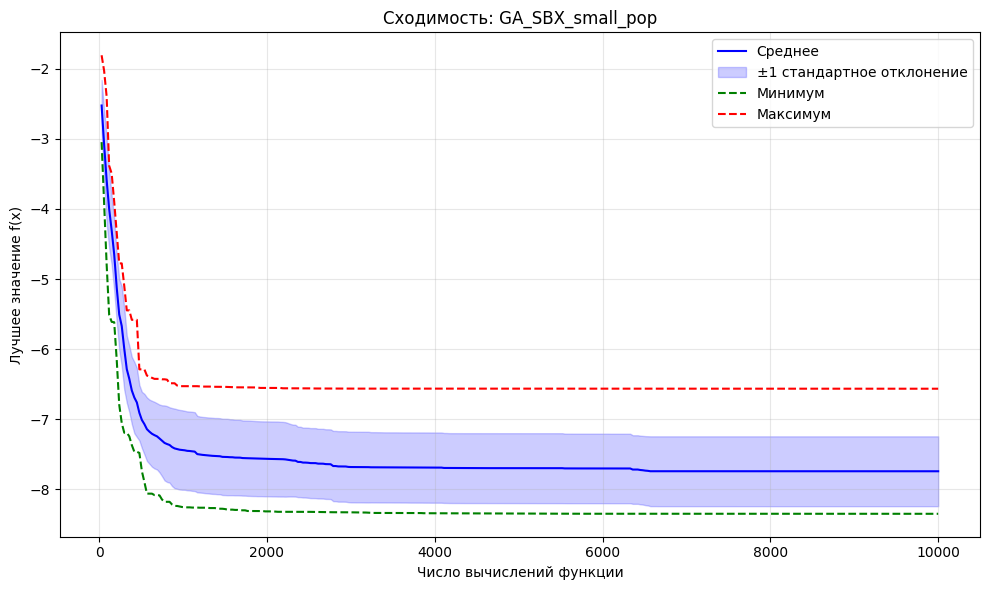

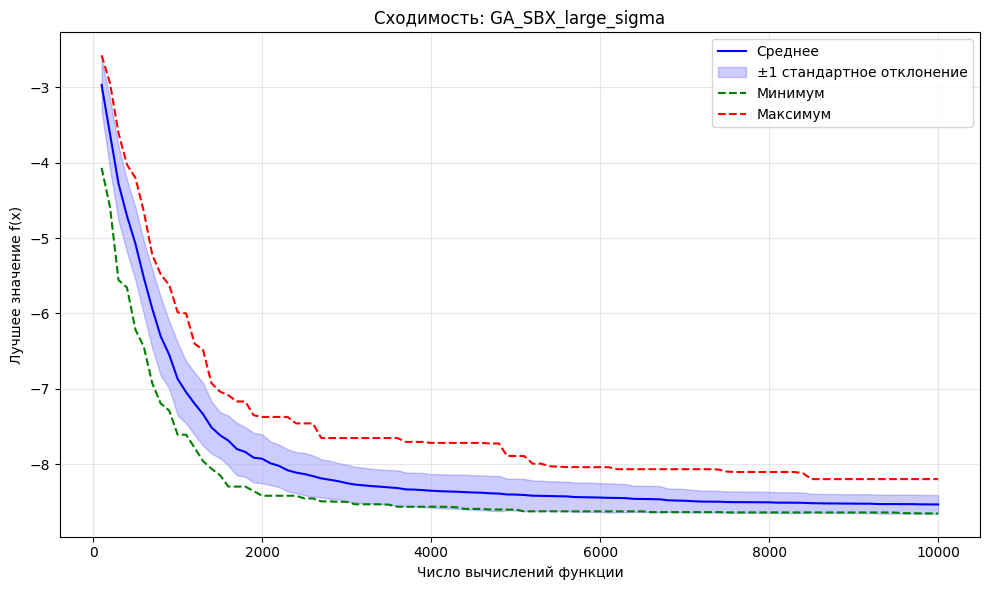

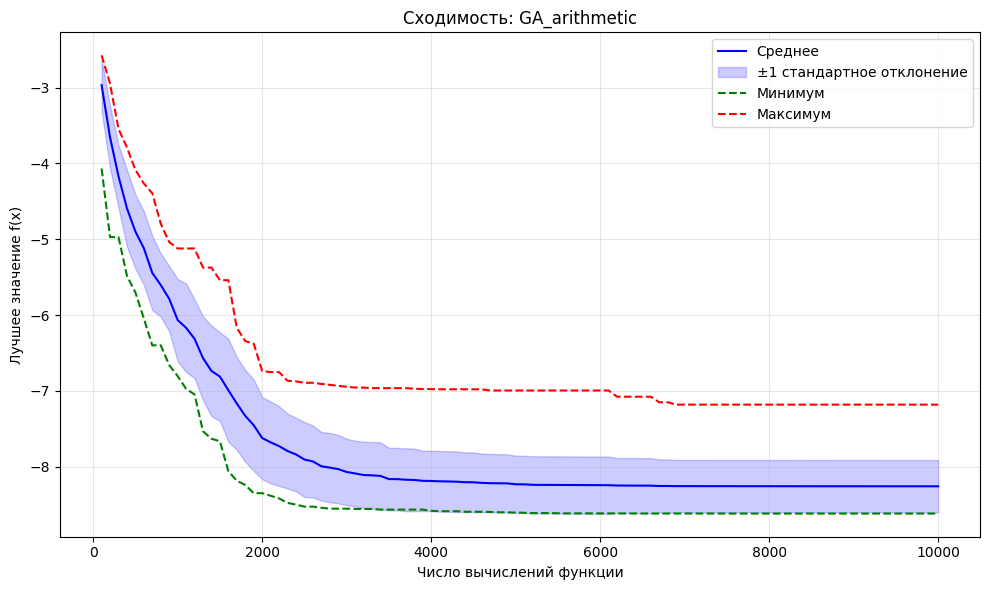

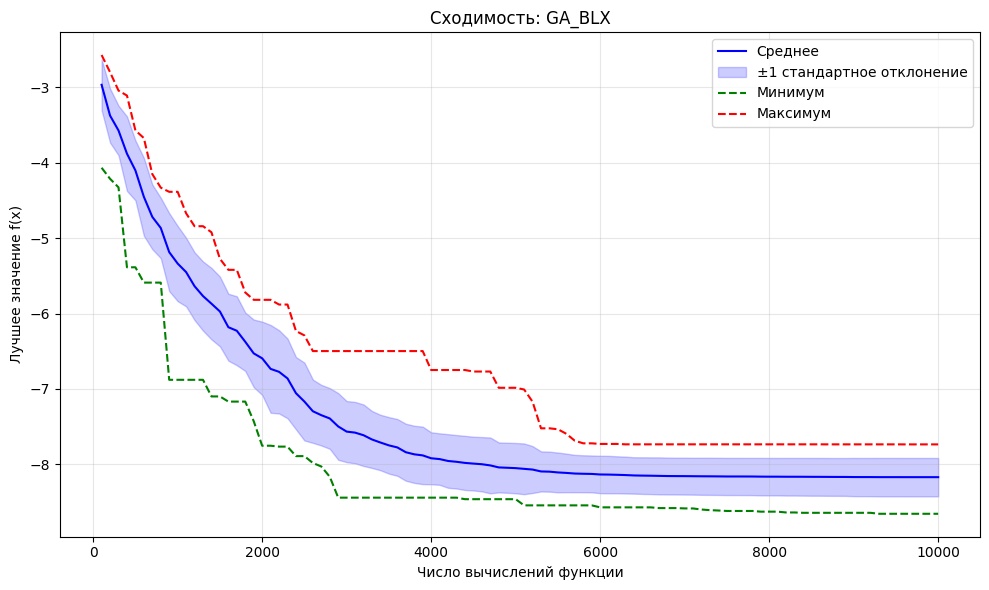

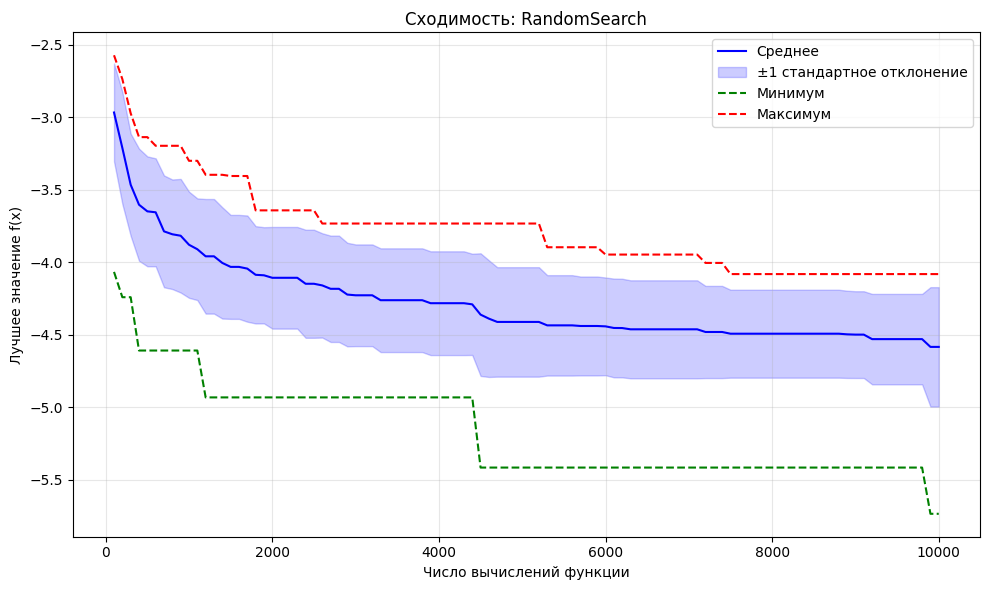

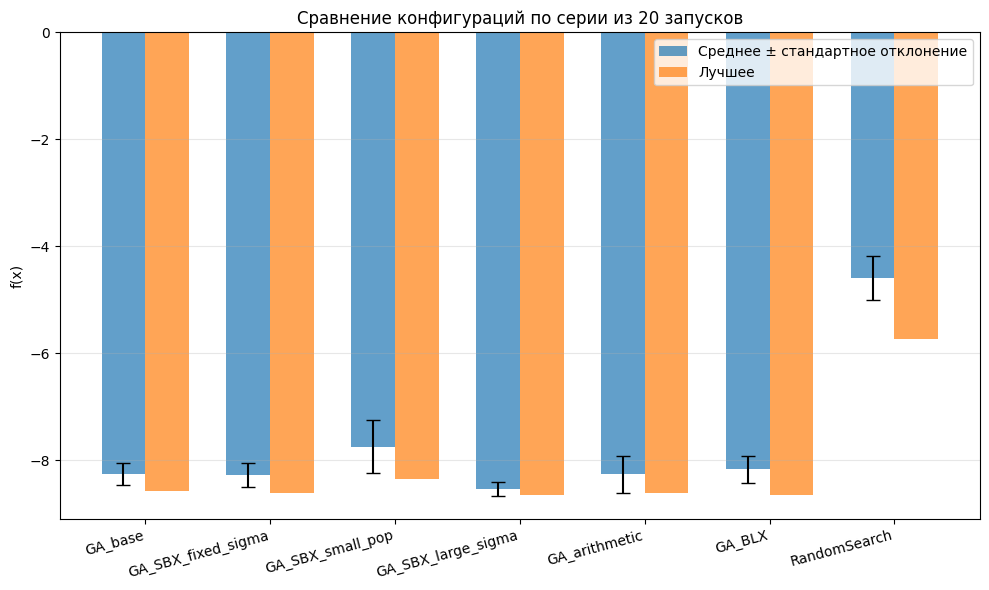

In [7]:
for name, results in all_results.items():
    plot_convergence(
        results,
        f"Сходимость: {name}",
        PLOTS_DIR / f"convergence_{name}.png",
    )

plot_comparison(all_summaries, PLOTS_DIR / "comparison.png")


## Как читать результаты

Сравнение по среднему значению показывает типичное качество метода, а стандартное отклонение — устойчивость между запусками. Лучший единичный результат приведён дополнительно и не заменяет статистику серии.

Размер популяции влияет на баланс между разнообразием и числом поколений при фиксированном бюджете. Начальное $\sigma$ управляет масштабом исследования, а кроссовер — способом объединения родительских координат. Поскольку альтернативы отличаются от базовой конфигурации только одним параметром, различия можно связать с соответствующим фактором.

Численные выводы по текущему запуску приведены в `report.md`.